# LAB019: curvas completas de fermentación y primera prueba EKF (0–166 h)

Comparamos tres trayectorias con las mismas condiciones iniciales y parámetros:
**simulación libre**, **EKF con CO₂** y **EKF con CO₂ + azúcar total/YAN a 22 y 40 h**.
Las curvas se calculan hasta la última muestra química, a 166 h, con el pulso de nitrógeno
registrado a 64,333 h. No se incorporan otras muestras químicas al filtro.
El pulso procede del calendario nutricional del dataset; el indicador automático del logger
permanece en cero y no se utiliza para reconstruir ese aporte.

El estado físico contiene únicamente **biomasa viable, nitrógeno, glucosa, fructosa, etanol,
CO₂ disuelto y O₂**. Biomasa muerta y glicerol no son estados, no tienen covarianzas y no
se grafican ni se evalúan. La memoria auxiliar necesaria para el modelo postnutrición se
explica en el anexo técnico.

**Cómo leer los resultados:** cada figura presenta una variable a lo largo de toda la
fermentación; los tres paneles corresponden a los tres escenarios y comparten escalas.
Las líneas son las trayectorias predichas, los círculos negros son muestras reservadas y
las estrellas rojas son exclusivamente las dos muestras de azúcar/YAN asimiladas.
La línea vertical gris identifica la nutrición. Se omiten bandas y diagramas de diagnóstico
de las figuras principales para facilitar la comparación de las curvas.

El ensayo es exploratorio. No se reajustan parámetros ni matrices contra las muestras
reservadas. Las matrices, comprobaciones y límites están después de las curvas.

**Traslado a wine-fermentation:** misma formulación y parámetros del primer EKF. Los datos químicos y parámetros de aquel ensayo se conservan como instantánea dentro del notebook; el registro continuo se lee de data/original de este repositorio. No se lee ni escribe pyomo-doe durante la ejecución. No se aplica aquí kLa=0.07 ni E0=9.8 de la comparación v2. Se conserva la restricción original por reducción global de ganancia; la proyección restringida discutida posteriormente NO se incorpora a esta reproducción. No se exportan CSV, JSON ni PNG.

Nutrition-associated analytical samples are included in the YAN RMSE and displayed as Samples. They remain evaluation data; the filter assimilation policy is unchanged.


In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, time
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/sources.csv').is_file())
sys.dont_write_bytecode=True
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation import model as base
get_ipython().run_line_magic('matplotlib', 'inline')

assert Path(sys.prefix).name.lower() == 'fermentation', sys.executable
path_parts = [p.rstrip('\\').lower() for p in os.environ['PATH'].split(';') if p]
lib = r'D:\anaconda3\envs\fermentation\Library\bin'.lower()
idaes = r'C:\Users\claud\AppData\Local\idaes\bin'.lower()
assert path_parts.index(lib) < path_parts.index(idaes) and path_parts.count(idaes) == 1
assert path_parts[-1] == idaes
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
HORIZON = 166.
CHEM_TIMES = (22., 40.)
BIN_H = .5
LOD = .05
FACTOR = 44.0095*60*.74/(1000*24.16*2)
PHYSICAL = ['X','N','G','F','E','Cd','O2']
STATE = PHYSICAL + ['X_ref','N_ref','G_ref','F_ref','E_ref']
NS = len(STATE)
NA = NS+1
IX = {s:i for i,s in enumerate(STATE)}
UNITS = ['g/L']*6+['mg/L']+['g/L']*5
CHANNELS = {'GF':'GF_g_l','N':'N_kg_m3','E':'E_g_l','X':'X_viable_g_l'}
RAW = ROOT/'data/original/natural/lab019_021'
INPUTS = [RAW/'backup_global_co2_completo.csv', RAW/'backup_global_temperatura_completo.csv', Path(base.__file__)]

def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda:f.read(2**20), b''): h.update(b)
    return h.hexdigest()
HASHES = {str(p.relative_to(ROOT)):sha(p) for p in INPUTS}
T0 = pd.Timestamp('2026-09-21 17:00:00', tz='America/Santiago').tz_convert('UTC')
print(sys.executable, '\nInicio UTC:', T0, '\nFuente biológica:', base.__file__)

D:\anaconda3\envs\fermentation\python.exe 
Inicio UTC: 2026-09-21 20:00:00+00:00 
Fuente biológica: D:\claud\Desktop\wine-fermentation\src\wine_fermentation\model.py


## Datos disponibles y qué se entrega al filtro

Se leen los registros crudos completos ya presentes en la caché LFS local, sin descargar ni
modificar datos. CO₂ se resume en ventanas completadas de 30 minutos; el tratamiento de picos
usa sólo los dos minutos previos. La temperatura se retiene desde el último minuto completado.
No se usa filtrado centrado ni información futura.

La química inicial se toma de la muestra previa a inoculación, conservando su mapeo histórico
a t=0 (desfase de 70 min). Biomasa viable inicial: inóculo común, sin ponderación con biomasa
posterior del lote. Las muestras completas de 22 y 40 h se excluyen del contraste reservado
para los tres escenarios, aunque sólo se asimilan azúcar total y YAN en el tercero.

In [2]:
# Instantánea exacta del primer ensayo; valores independientes de configs actuales.
THETA_RECORDS=[{'parameter': 'mu0', 'theta': 0.078727916784474, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'sN', 'theta': 8.751445870938538, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'qN', 'theta': 0.021080382428485, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'qXG', 'theta': 0.081490986404658, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'qXF', 'theta': 0.070932706501538, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'betaG0', 'theta': 0.428878002997387, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'sG', 'theta': 0.097455098738674, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'betaF0', 'theta': 3.440399174765835, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'sF', 'theta': 0.178295205517654, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'qEG', 'theta': 1.712806793770099, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'qEF', 'theta': 5.023016750172416, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'iG', 'theta': 0.056037437269564, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'iE', 'theta': 0.04016794097998, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'Kd0', 'theta': 0.000150249547897, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'm0', 'theta': 0.018338579392877, 'source': 'shared\\results\\new_must_glycerol_overnight_validation\\theta_multistart_07.csv'}, {'parameter': 'gammaG0', 'theta': 0.115558791367503, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}, {'parameter': 'gammaF0', 'theta': 0.000100001621599, 'source': 'laboratory_2026\\results\\estimability_historical_natural\\theta.csv'}]
CHEM_RECORDS=[{'lab': 'LAB019', 'sample': '1', 'sample_timestamp': '2026-09-21 15:50:00', 'sample_t_h': -1.166666666666667, 't_h': 0.0, 'metadata_fallback': False, 'density': 1067.6, 'Brix': 16.9, 'GF_g_l': 158.16, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 158.16, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 79.19, 'G_raw_g_l': 79.19, 'F_g_l': 78.97, 'PAN_mg_l': 116.0, 'NH3_raw_mg_l': 175.0, 'NH3_censored_mg_l': 175.0, 'Gly_g_l': 1.22, 'Pyr_mg_l': 11.0, 'Etanol_pct_vv': 1.53, 'E_g_l': 12.075372000000002, 'AcAld_mg_l': None, 'Acetate_g_l': 0.15, 'G_raw_text': '79,19', 'GF_raw_text': '158,16', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 0.0, 'time_upper_h': 0.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': True, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 0.8595, 'X_viable_g_l': 0.82950345, 'Xd_g_l': 0.02999655, 'YAN_mg_l': 230.025, 'N_kg_m3': 0.230025}, {'lab': 'LAB019', 'sample': '2', 'sample_timestamp': '2026-09-22 09:00:00', 'sample_t_h': 16.0, 't_h': 16.0, 'metadata_fallback': False, 'density': 1065.8, 'Brix': 16.5, 'GF_g_l': 144.94, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 144.94, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 73.14, 'G_raw_g_l': 73.14, 'F_g_l': 71.8, 'PAN_mg_l': 97.0, 'NH3_raw_mg_l': 164.0, 'NH3_censored_mg_l': 164.0, 'Gly_g_l': 1.39, 'Pyr_mg_l': 31.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 134.0, 'Acetate_g_l': 0.14, 'G_raw_text': '73,14', 'GF_raw_text': '144,94', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 16.0, 'time_upper_h': 16.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 0.3801, 'X_viable_g_l': 0.35592564, 'Xd_g_l': 0.02417436, 'YAN_mg_l': 201.972, 'N_kg_m3': 0.201972}, {'lab': 'LAB019', 'sample': '3', 'sample_timestamp': '2026-09-22 12:00:00', 'sample_t_h': 19.0, 't_h': 19.0, 'metadata_fallback': False, 'density': 1065.4, 'Brix': 16.5, 'GF_g_l': 145.55, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 145.55, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 76.17, 'G_raw_g_l': 76.17, 'F_g_l': 69.38000000000001, 'PAN_mg_l': 88.0, 'NH3_raw_mg_l': 157.0, 'NH3_censored_mg_l': 157.0, 'Gly_g_l': 1.29, 'Pyr_mg_l': 38.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 141.0, 'Acetate_g_l': 0.15, 'G_raw_text': '76,17', 'GF_raw_text': '145,55', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 19.0, 'time_upper_h': 19.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 0.4263, 'X_viable_g_l': 0.41594091, 'Xd_g_l': 0.01035909, 'YAN_mg_l': 187.211, 'N_kg_m3': 0.187211}, {'lab': 'LAB019', 'sample': '4', 'sample_timestamp': '2026-09-22 15:00:00', 'sample_t_h': 22.0, 't_h': 22.0, 'metadata_fallback': False, 'density': 1063.8, 'Brix': 16.2, 'GF_g_l': 151.22, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 151.22, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 71.97, 'G_raw_g_l': 71.97, 'F_g_l': 79.25, 'PAN_mg_l': 84.0, 'NH3_raw_mg_l': 157.0, 'NH3_censored_mg_l': 157.0, 'Gly_g_l': 1.61, 'Pyr_mg_l': 43.0, 'Etanol_pct_vv': 1.74, 'E_g_l': 13.732776, 'AcAld_mg_l': 168.0, 'Acetate_g_l': 0.15, 'G_raw_text': '71,97', 'GF_raw_text': '151,22', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 22.0, 'time_upper_h': 22.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': True, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 0.4377, 'X_viable_g_l': 0.42846453, 'Xd_g_l': 0.00923547, 'YAN_mg_l': 183.211, 'N_kg_m3': 0.183211}, {'lab': 'LAB019', 'sample': '5', 'sample_timestamp': '2026-09-23 09:00:00', 'sample_t_h': 40.0, 't_h': 40.0, 'metadata_fallback': False, 'density': 1058.3, 'Brix': 14.8, 'GF_g_l': 136.87, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 136.87, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': None, 'G_raw_g_l': None, 'F_g_l': None, 'PAN_mg_l': 63.0, 'NH3_raw_mg_l': 118.0, 'NH3_censored_mg_l': 118.0, 'Gly_g_l': 2.46, 'Pyr_mg_l': 92.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 235.0, 'Acetate_g_l': 0.28, 'G_raw_text': 'Out', 'GF_raw_text': '136,87', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 40.0, 'time_upper_h': 40.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.2225, 'X_viable_g_l': 1.22139975, 'Xd_g_l': 0.00110025, 'YAN_mg_l': 130.114, 'N_kg_m3': 0.130114}, {'lab': 'LAB019', 'sample': '6', 'sample_timestamp': '2026-09-23 12:00:00', 'sample_t_h': 43.0, 't_h': 43.0, 'metadata_fallback': False, 'density': 1055.7, 'Brix': 14.2, 'GF_g_l': 129.5, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 129.5, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': None, 'G_raw_g_l': None, 'F_g_l': None, 'PAN_mg_l': 50.0, 'NH3_raw_mg_l': 97.0, 'NH3_censored_mg_l': 97.0, 'Gly_g_l': 2.82, 'Pyr_mg_l': 95.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 327.0, 'Acetate_g_l': 0.3, 'G_raw_text': 'Out', 'GF_raw_text': '129,50', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 43.0, 'time_upper_h': 43.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.2225, 'X_viable_g_l': 1.21675425, 'Xd_g_l': 0.00574575, 'YAN_mg_l': 99.831, 'N_kg_m3': 0.099831}, {'lab': 'LAB019', 'sample': '7', 'sample_timestamp': '2026-09-23 15:00:00', 'sample_t_h': 46.0, 't_h': 46.0, 'metadata_fallback': False, 'density': 1052.8, 'Brix': 13.7, 'GF_g_l': 127.72, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 127.72, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': None, 'G_raw_g_l': None, 'F_g_l': None, 'PAN_mg_l': 44.0, 'NH3_raw_mg_l': 78.0, 'NH3_censored_mg_l': 78.0, 'Gly_g_l': 2.75, 'Pyr_mg_l': 99.0, 'Etanol_pct_vv': 2.31, 'E_g_l': 18.231444, 'AcAld_mg_l': 215.0, 'Acetate_g_l': 0.29, 'G_raw_text': 'Out', 'GF_raw_text': '127,72', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 46.0, 'time_upper_h': 46.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.6314, 'X_viable_g_l': 1.62683208, 'Xd_g_l': 0.00456792, 'YAN_mg_l': 78.194, 'N_kg_m3': 0.078194}, {'lab': 'LAB019', 'sample': '8', 'sample_timestamp': '2026-09-24 09:00:00', 'sample_t_h': 64.0, 't_h': 64.0, 'metadata_fallback': False, 'density': 1038.4, 'Brix': 10.1, 'GF_g_l': 89.86, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 89.86, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 35.1, 'G_raw_g_l': 35.1, 'F_g_l': 54.76, 'PAN_mg_l': 30.0, 'NH3_raw_mg_l': -2.0, 'NH3_censored_mg_l': 0.0, 'Gly_g_l': 3.96, 'Pyr_mg_l': 88.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 195.0, 'Acetate_g_l': None, 'G_raw_text': '35,10', 'GF_raw_text': '89,86', 'GF_low_raw_text': None, 'NH3_below_zero': True, 'YAN_reported_mg_l': None, 'time_lower_h': 64.0, 'time_upper_h': 64.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.6383, 'X_viable_g_l': 1.6268319, 'Xd_g_l': 0.0114681, 'YAN_mg_l': 0.0, 'N_kg_m3': 0.0}, {'lab': 'LAB019', 'sample': 'NUT', 'sample_timestamp': None, 'sample_t_h': 64.51555555555555, 't_h': 64.51555555555555, 'metadata_fallback': True, 'density': None, 'Brix': None, 'GF_g_l': None, 'GF_source': None, 'GF_zero_substitution': False, 'GF_320_raw_g_l': None, 'GF_low_raw_g_l': None, 'GF_320_below_zero': None, 'G_g_l': None, 'G_raw_g_l': None, 'F_g_l': None, 'PAN_mg_l': 52.0, 'NH3_raw_mg_l': 58.0, 'NH3_censored_mg_l': 58.0, 'Gly_g_l': None, 'Pyr_mg_l': None, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': None, 'Acetate_g_l': None, 'G_raw_text': None, 'GF_raw_text': None, 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': 100.0, 'time_lower_h': 64.33333333333333, 'time_upper_h': 64.69777777777777, 'time_provisional': True, 'time_source': 'midpoint of assumed post-pulse/pre-analysis interval; extraction unknown', 'is_NUT': True, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': True, 'y15_available': True, 'X_total_g_l': None, 'X_viable_g_l': None, 'Xd_g_l': None, 'YAN_mg_l': 69.734, 'N_kg_m3': 0.069734}, {'lab': 'LAB019', 'sample': '9', 'sample_timestamp': '2026-09-24 12:30:00', 'sample_t_h': 67.5, 't_h': 67.5, 'metadata_fallback': False, 'density': 1034.4, 'Brix': 9.2, 'GF_g_l': 81.43, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 81.43, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 30.07, 'G_raw_g_l': 30.07, 'F_g_l': 51.36000000000001, 'PAN_mg_l': 40.0, 'NH3_raw_mg_l': 31.0, 'NH3_censored_mg_l': 31.0, 'Gly_g_l': 4.15, 'Pyr_mg_l': 93.0, 'Etanol_pct_vv': None, 'E_g_l': None, 'AcAld_mg_l': 310.0, 'Acetate_g_l': 0.31, 'G_raw_text': '30,07', 'GF_raw_text': '81,43', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 67.5, 'time_upper_h': 67.5, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 2.1636, 'X_viable_g_l': 2.15905644, 'Xd_g_l': 0.00454356, 'YAN_mg_l': 35.513, 'N_kg_m3': 0.035513}, {'lab': 'LAB019', 'sample': '10', 'sample_timestamp': '2026-09-24 15:30:00', 'sample_t_h': 70.5, 't_h': 70.5, 'metadata_fallback': False, 'density': 1029.6, 'Brix': 8.1, 'GF_g_l': 72.34, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 72.34, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 24.73, 'G_raw_g_l': 24.73, 'F_g_l': 47.61, 'PAN_mg_l': 36.0, 'NH3_raw_mg_l': 16.0, 'NH3_censored_mg_l': 16.0, 'Gly_g_l': 4.71, 'Pyr_mg_l': 79.0, 'Etanol_pct_vv': 4.19, 'E_g_l': 33.06915600000001, 'AcAld_mg_l': 288.0, 'Acetate_g_l': 0.31, 'G_raw_text': '24,73', 'GF_raw_text': '72,34', 'GF_low_raw_text': None, 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 70.5, 'time_upper_h': 70.5, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.8663, 'X_viable_g_l': 1.86163425, 'Xd_g_l': 0.00466575, 'YAN_mg_l': 19.168, 'N_kg_m3': 0.019168}, {'lab': 'LAB019', 'sample': '11', 'sample_timestamp': '2026-09-25 08:30:00', 'sample_t_h': 87.5, 't_h': 87.5, 'metadata_fallback': False, 'density': 1017.1, 'Brix': 4.9, 'GF_g_l': 43.07, 'GF_source': 'GLU-FRU-320', 'GF_zero_substitution': False, 'GF_320_raw_g_l': 43.07, 'GF_low_raw_g_l': None, 'GF_320_below_zero': False, 'G_g_l': 10.58, 'G_raw_g_l': 10.58, 'F_g_l': 32.49, 'PAN_mg_l': 21.0, 'NH3_raw_mg_l': -4.0, 'NH3_censored_mg_l': 0.0, 'Gly_g_l': 4.91, 'Pyr_mg_l': 39.0, 'Etanol_pct_vv': 6.13, 'E_g_l': 48.380412, 'AcAld_mg_l': 166.0, 'Acetate_g_l': 0.3, 'G_raw_text': '10,58', 'GF_raw_text': '43,07', 'GF_low_raw_text': None, 'NH3_below_zero': True, 'YAN_reported_mg_l': None, 'time_lower_h': 87.5, 'time_upper_h': 87.5, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': 1.1037, 'X_viable_g_l': 1.08063267, 'Xd_g_l': 0.02306733, 'YAN_mg_l': 0.0, 'N_kg_m3': 0.0}, {'lab': 'LAB019', 'sample': '12', 'sample_timestamp': '2026-09-28 15:00:00', 'sample_t_h': 166.0, 't_h': 166.0, 'metadata_fallback': False, 'density': 994.2, 'Brix': -0.9, 'GF_g_l': 0.0, 'GF_source': 'GLUCOSE-FRUCTOSE: resultado final negativo aproximado a 0', 'GF_zero_substitution': True, 'GF_320_raw_g_l': -1.85, 'GF_low_raw_g_l': -0.03, 'GF_320_below_zero': True, 'G_g_l': None, 'G_raw_g_l': -0.03, 'F_g_l': None, 'PAN_mg_l': 33.0, 'NH3_raw_mg_l': 1.0, 'NH3_censored_mg_l': 1.0, 'Gly_g_l': 5.56, 'Pyr_mg_l': 28.0, 'Etanol_pct_vv': 9.91, 'E_g_l': 78.213684, 'AcAld_mg_l': 117.0, 'Acetate_g_l': 0.31, 'G_raw_text': '-0,03', 'GF_raw_text': '-1,85', 'GF_low_raw_text': '-0,03', 'NH3_below_zero': False, 'YAN_reported_mg_l': None, 'time_lower_h': 166.0, 'time_upper_h': 166.0, 'time_provisional': False, 'time_source': 'offline extraction timestamp; m1 mapped to t0', 'is_NUT': False, 'is_initial': False, 'soft_flag_GF': False, 'soft_flag_metadata': False, 'y15_available': True, 'X_total_g_l': None, 'X_viable_g_l': None, 'Xd_g_l': None, 'YAN_mg_l': 3.823, 'N_kg_m3': 0.003823}]
INOC_SNAPSHOT={'user_viable_million_ml': 25.04, 'mean_viable_million_ml': 16.88, 'relative_weight': 1.483412322274882, 'common_viable_million_ml': 6.362850000000001, 'weighted_viable_million_ml': 9.438730094786733, 'weighted_X0_g_l': 0.283161902843602, 'common_X0_g_l': 0.1908855, 'new_common_Xd0_g_l': 0.032661, 'previous_X0_g_l': 0.8595, 'previous_Xd0_g_l': 0.02999655, 'common_X_ratio_to_section_16_1': 1.001547926213314, 'N_pulses': '((64.33333333333333, 0.08),)', 'end_h': 166.0}
FROZEN_GAS={'kCO2_release_h': 0.4245882713532321, 'CO2sat_scale': 0.351389541106575, 'O2_qmax_mg_gdw_h': 0.15, 'O2_initial_scale': 0.1953996656508908, 'pulse_t_rise_h': 64.65870374633818, 'pulse_activity_gain': 0.25, 'chem_activation_start_fraction': 0.735056695858678, 'chem_activation_duration_fraction': 1.063909868135744, 'matrix_gain': 0.8807487423194738, 'A': 0.3, 'tau_rise_h': 4.0, 'tau_decay_h': 12.0, 'N_ref_g_l': 0.14, 'kernel_normalization': 'analytic_peak'}
FROZEN_SELECTION={'temperature': 'reference_20_45', 'filtering': 'offline_30min', 'mode': 'v2', 'theta': 'theta_full', 'training': 'train_016_018', 'labs': 'LAB016,LAB017,LAB018', 'stage': 'Z1', 'success': True, 'objective': 0.059046077236599, 'jacobian_ratio': None, 'active_bounds': None, 'kCO2_release_h': 0.424588271353232, 'CO2sat_scale': 0.351389541106575, 'matrix_gain': 0.880748742319474, 'pulse_activity_gain': None, 'pulse_t_rise_h': None}
N_EVENTS_SNAPSHOT=((64.33333333333333, 0.08),)
ORIGINAL_HASHES={'fermentation_model\\laboratory_2026\\notebooks\\EKF\\lab019_first_ekf_full_batch.source.ipynb': 'ce2eb62c21fe1b8073f638dbb56fb1bb2ae71a9f421795e08415c7d16c9094f3', 'fermentation_model\\laboratory_2026\\results\\estimability_historical_natural\\theta_natural_full.csv': '3876c53d0b4dc6f4126ffb4f8e0999a8455c90f283c345a110be33e86504b46e', 'fermentation_model\\laboratory_2026\\results\\nitrogen_consumption_diagnosis\\inoculum_viable_weighted\\initial_conditions.csv': '0ccfa4607c2d2e7494af14f0ec7d65b16ae63caab31a30770305484e708a4ae0', 'fermentation_model\\laboratory_2026\\results\\co2_lab016_021_recalibration_v2\\chemistry_observations_corrected_YAN.csv': 'caf299f8fe5ff92b42808cf791a0cce5600f220729ed768c37d2369ef6b796b3', 'fermentation_model\\laboratory_2026\\results\\co2_lab016_021_recalibration_v2\\manifest.json': 'f9c5efdc19c67bbb16d8eec30f76060f07f090b23422d6b5b7e869def6b37e68', 'fermentation_model\\laboratory_2026\\notebooks\\diagnostics\\co2_lab016_021_recalibration_v3_artifacts\\fit_parameters.csv': 'e9da3ed11cc4f529866326fadfc682a4dbb836473d72ecdcef4e360b104bf369'}
def local_content(path):
    head=path.read_bytes()[:200] if path.stat().st_size<1024 else b''
    if not head.startswith(b'version https://git-lfs.github.com/spec/v1'):return path
    oid=next(line.split('sha256:')[1] for line in head.decode().splitlines() if line.startswith('oid '))
    content=ROOT/'.git/lfs/objects'/oid[:2]/oid[2:4]/oid
    assert content.is_file() and sha(content)==oid, f'Objeto LFS local no disponible: {oid}'
    if content not in INPUTS:
        INPUTS.append(content);HASHES[str(content.relative_to(ROOT))]=oid
    return content

def read_raw(path, columns):
    path=local_content(path)
    pieces=[]
    lo = (T0-pd.Timedelta(hours=1)).tz_convert('America/Santiago').tz_localize(None)
    hi = (T0+pd.Timedelta(hours=HORIZON)).tz_convert('America/Santiago').tz_localize(None)
    for chunk in pd.read_csv(path, usecols=columns, chunksize=300000):
        stamp = pd.to_datetime(chunk.timestamp, errors='raise')
        keep = chunk.fermentador.eq('F1') & stamp.between(lo,hi)
        if keep.any():
            part=chunk.loc[keep].copy()
            part['timestamp']=pd.DatetimeIndex(stamp[keep]).tz_localize(
                'America/Santiago', ambiguous='raise', nonexistent='raise').tz_convert('UTC')
            pieces.append(part)
    out=pd.concat(pieces).sort_values('timestamp').reset_index(drop=True)
    assert out.timestamp.is_unique
    out['t_h']=(out.timestamp-T0).dt.total_seconds()/3600
    return out

raw_gas=read_raw(RAW/'backup_global_co2_completo.csv',['timestamp','fermentador','flow_sccm','status'])
raw_temp=read_raw(RAW/'backup_global_temperatura_completo.csv',['timestamp','fermentador','T','nutricion_activa'])
assert raw_gas.t_h.max() > HORIZON-1/60 and raw_temp.t_h.max() > HORIZON-1/60
print('Estados de nutrición en logger:',raw_temp.nutricion_activa.astype(str).value_counts().to_dict())

# Robust causal despiking: the reference window ends at the sample being processed.
flow=raw_gas.set_index('timestamp').flow_sccm.astype(float)
roll=flow.rolling('120s', min_periods=5)
median=roll.median()
mad=roll.apply(lambda a:np.median(np.abs(a-np.median(a))),raw=True)
spike=(flow-median).abs() > np.maximum(3.5*1.4826*mad,.5)
clean=flow.where(~spike,median)
raw_gas['despiked_sccm']=clean.to_numpy()
raw_gas['spike']=spike.to_numpy()
rows=[]
for end in np.arange(BIN_H,HORIZON+1e-8,BIN_H):
    d=raw_gas[raw_gas.t_h.gt(end-BIN_H)&raw_gas.t_h.le(end)]
    gaps=np.diff(np.r_[end-BIN_H,d.t_h.to_numpy(),end])
    valid=len(d)>=30 and gaps.max()<=2/60
    rows.append(dict(t_h=end, q=d.despiked_sccm.mean()*FACTOR,
                     q_raw=d.flow_sccm.mean()*FACTOR,n=len(d),valid=valid,
                     max_gap_min=60*gaps.max(),spikes=int(d.spike.sum())))
gas_obs=pd.DataFrame(rows)
eligible=gas_obs.valid & gas_obs.q.ge(LOD)
gas_obs['assimilate']=eligible & eligible.shift(fill_value=False)
print('Ventanas sin soporte suficiente (no asimiladas):',int((~gas_obs.valid).sum()))

# Causal temperature: median of each completed minute, held until next completion.
raw_temp['minute']=np.floor(raw_temp.t_h*60).astype(int)
temp=raw_temp.groupby('minute').agg(T=('T','median'),last=('t_h','max')).reset_index()
temp['available_h']=(temp.minute+1)/60
def temperature(t):
    j=np.searchsorted(temp.available_h.to_numpy(),t+1e-12,side='right')-1
    assert j>=0
    assert temp.available_h.iloc[j]<=t+1e-10
    return float(temp['T'].iloc[j])

chem=pd.DataFrame(CHEM_RECORDS)
chem=chem[chem.lab.eq('LAB019') & chem.t_h.between(0,HORIZON)].copy()
chem=chem.sort_values('t_h')  # Nutrition samples remain in held-out evaluation.
chem['role']=np.where(chem.t_h.eq(0),'inicial',
                     np.where(chem.t_h.isin(CHEM_TIMES),'asimilable GF+N / muestra excluida','reservada'))
display(chem[['sample','t_h','role','GF_g_l','N_kg_m3','E_g_l','GF_zero_substitution']])
display(gas_obs.agg({'n':['min','max'],'q':['min','max'],'max_gap_min':['max'],'spikes':['sum']}))
print('Bins de CO₂:',len(gas_obs),'asimilados:',gas_obs.assimilate.sum(),
      'primera disponibilidad:',gas_obs.loc[gas_obs.assimilate,'t_h'].min())

Estados de nutrición en logger: {'0': 172748}
Ventanas sin soporte suficiente (no asimiladas): 0
Bins de CO₂: 332 asimilados: 208 primera disponibilidad: 23.0


,sample,t_h,role,GF_g_l,N_kg_m3,E_g_l,GF_zero_substitution
0,1,0.000000,inicial,158.16,0.230025,12.075372,False
1,2,16.000000,reservada,144.94,0.201972,NaN,False
2,3,19.000000,reservada,145.55,0.187211,NaN,False
3,4,22.000000,asimilable GF+N / muestra excluida,151.22,0.183211,13.732776,False
4,5,40.000000,asimilable GF+N / muestra excluida,136.87,0.130114,NaN,False
5,6,43.000000,reservada,129.50,0.099831,NaN,False
6,7,46.000000,reservada,127.72,0.078194,18.231444,False
7,8,64.000000,reservada,89.86,0.000000,NaN,False
8,NUT,64.515556,reservada,NaN,0.069734,NaN,False
9,9,67.500000,reservada,81.43,0.035513,NaN,False


,n,q,max_gap_min,spikes
min,108.0,0.001717,NaN,NaN
max,176.0,0.731374,0.366667,NaN
sum,NaN,NaN,NaN,5035.0


In [3]:
theta_table=pd.DataFrame(THETA_RECORDS)
theta=dict(zip(theta_table.parameter,theta_table.theta))
gas_params=FROZEN_GAS.copy()
choice=pd.DataFrame([FROZEN_SELECTION])
ini=chem.loc[chem.t_h.eq(0)].iloc[0]
inoc=pd.Series(INOC_SNAPSHOT)
N_EVENTS=N_EVENTS_SNAPSHOT
assert len(N_EVENTS)==1 and abs(N_EVENTS[0][0]-64.3333333333333)<1e-8
TP,DOSE=map(float,N_EVENTS[0])
oxygen0=gas_params['O2_initial_scale']*max(8.6*np.exp(-.024*(temperature(0)-20)
                      -.002*max(ini.E_g_l,0)-.001*max(ini.G_g_l+ini.F_g_l,0)),1e-6)
physical0=np.array([inoc.common_X0_g_l,ini.N_kg_m3,ini.G_g_l,ini.F_g_l,ini.E_g_l,0.,oxygen0])
x0=np.r_[physical0,physical0[:5]]
S0=x0[2]+x0[3]
SCALE=np.r_[[.3,.25,80.,80.,15.,.2,2.],[.3,.25,80.,80.,15.]]
sd0=np.array([x0[0],.015,1.,np.sqrt(5),.5,.05,.5*x0[6]])
Pphysical=np.diag(sd0**2);Pphysical[2,3]=Pphysical[3,2]=-1.
# Reference memory starts from exactly the same uncertain initial biological state.
B=np.vstack([np.eye(7),np.eye(7)[:5]])
P0=B@Pphysical@B.T
P0z=P0/np.outer(SCALE,SCALE)
Rgas=.04**2;Rchem=np.diag([2.**2,.015**2])
display(pd.DataFrame({'variable':PHYSICAL,'inicial':physical0,'sigma_inicial':sd0,
                      'unidad':['g/L']*6+['mg/L']}))
print(f'Nutrición: +{DOSE:.3f} g/L de N a {TP:.3f} h. Química asimilada: {CHEM_TIMES} h.')
display(pd.Series(gas_params,name="Parámetros de gas del primer EKF"))
display(theta_table[["parameter","theta"]])
display(pd.Series(ORIGINAL_HASHES,name="SHA256 de las fuentes de la instantánea"))


Nutrición: +0.080 g/L de N a 64.333 h. Química asimilada: (22.0, 40.0) h.


,variable,inicial,sigma_inicial,unidad
0,X,0.190886,0.190886,g/L
1,N,0.230025,0.015000,g/L
2,G,79.190000,1.000000,g/L
3,F,78.970000,2.236068,g/L
4,E,12.075372,0.500000,g/L
5,Cd,0.000000,0.050000,g/L
6,O2,1.497719,0.748859,mg/L


kCO2_release_h                            0.424588
CO2sat_scale                               0.35139
O2_qmax_mg_gdw_h                              0.15
O2_initial_scale                            0.1954
pulse_t_rise_h                           64.658704
pulse_activity_gain                           0.25
chem_activation_start_fraction            0.735057
chem_activation_duration_fraction          1.06391
matrix_gain                               0.880749
A                                              0.3
tau_rise_h                                     4.0
tau_decay_h                                   12.0
N_ref_g_l                                     0.14
kernel_normalization                 analytic_peak
Name: Parámetros de gas del primer EKF, dtype: object

,parameter,theta
0,mu0,0.078728
1,sN,8.751446
2,qN,0.021080
3,qXG,0.081491
4,qXF,0.070933
5,betaG0,0.428878
6,sG,0.097455
7,betaF0,3.440399
8,sF,0.178295
9,qEG,1.712807


fermentation_model\laboratory_2026\notebooks\EKF\lab019_first_ekf_full_batch.source.ipynb                                    ce2eb62c21fe1b8073f638dbb56fb1bb2ae71a9f421795...
fermentation_model\laboratory_2026\results\estimability_historical_natural\theta_natural_full.csv                            3876c53d0b4dc6f4126ffb4f8e0999a8455c90f283c345...
fermentation_model\laboratory_2026\results\nitrogen_consumption_diagnosis\inoculum_viable_weighted\initial_conditions.csv    0ccfa4607c2d2e7494af14f0ec7d65b16ae63caab31a30...
fermentation_model\laboratory_2026\results\co2_lab016_021_recalibration_v2\chemistry_observations_corrected_YAN.csv          caf299f8fe5ff92b42808cf791a0cce5600f220729ed76...
fermentation_model\laboratory_2026\results\co2_lab016_021_recalibration_v2\manifest.json                                     f9c5efdc19c67bbb16d8eec30f76060f07f090b23422d6...
fermentation_model\laboratory_2026\notebooks\diagnostics\co2_lab016_021_recalibration_v3_artifacts\fit_parameters.csv        

## Especificación explícita del primer EKF reproducido

Se mantienen **theta_full natural original, su fuente fermentativa y sus restricciones numéricas**, sin recalibración y sin sustituirlos por los parámetros de los modelos nuevos. La fase de adaptación fisiológica no está modelada. Los parámetros completos se imprimen arriba.

Las cinco ecuaciones biológicas son:
\[
\dot X=(\mu-k_d)X,\quad \dot N=-\mu X/Y_{X/N},
\]
\[
\dot G=-[\mu/Y_{X/G}+\beta_G/Y_{E/G}+m_{\mathrm{ef}}G/(G+F)]X,
\quad \dot F=-[\mu/Y_{X/F}+\beta_F/Y_{E/F}+m_{\mathrm{ef}}F/(G+F)]X,
\quad \dot E=(\beta_G+\beta_F)X.
\]
En el código se usan los cocientes heredados y tolerancias epsilon equivalentes. Mortalidad, leyes térmicas y mantenimiento atenuado son los originales; se verifican las cinco ecuaciones contra el módulo actual reducido.

La fuente previa a modulaciones de gas usa **44.01/46.07 por la producción de etanol**, no el término de crecimiento añadido en los modelos de compare_models. Se integran una trayectoria con N y una referencia sin N. La rampa es r=clip((t−64.333)/64.6587,0,1); la actividad histórica es 1+(0.25−1)r. La producción combinada es el máximo no negativo de esa actividad por la producción sin pulso más r por el incremento con pulso. Se multiplica por el transitorio causal de todos los pulsos (aquí uno), A=0.30, tau_r=4 h, tau_d=12 h, normalizado por su máximo analítico y por la dosis de referencia 0.14 g/L.

La puerta gaseosa usa consumo predicho de G+F entre 2 y 10 g/L, smoothstep 3z²−2z³. La modulación de O₂ es 0.08+0.92·0.75²/(0.75²+O₂²). El O₂ se consume con qmax=0.15 y semisaturación 0.25 mg/L sobre la biomasa interpolada con la misma rampa con/sin nutrición.

\[
C_{sat}=s\,1.69e^{-0.032(T-20)}e^{0.0016E}e^{-0.0012(G+F)},
\quad q_{gas}=k C_d\left(0.05+0.95\frac{C_d}{C_d+C_{sat}}\right),
\quad \dot C_d=q_{prod}-q_{gas}.
\]
La medición predicha es la ganancia por la emisión **media de cada ventana completada de 30 min**, no un valor instantáneo. k=0.424588 h⁻¹, s=0.351390 y ganancia=0.880749, provenientes de Z1 entrenado en LAB016–018. El volumen de conversión del sensor se conserva en 2 L. No se aplica la corrección posterior por volumen remanente.

**Datos:** iniciales de m1 (muestra previa a inoculación mapeada a t=0); X0 del inóculo común; CO₂ crudo con despiking causal de 120 s y medias completadas de 30 min; temperatura del último minuto completado. Se corrige con CO₂ sólo cuando la ventana actual y la anterior son válidas y ≥0.05 g/(L·h). Los puntos bajos se omiten: no se aplica filtro censurado. Sólo se asimilan G+F y N a 22/40 h en el tercer escenario. La muestra NUT se incluye en la tabla y en el RMSE reservado; el pulso +0.08 g/L a 64.333 h se incorpora desde el calendario. Etanol y biomasa posteriores nunca se asimilan; se reserva el resto de muestras y se excluye G+F final censurado del error.

**Matrices:** P0 se fija desde las incertidumbres iniciales; incluye cov(G,F)=−1 y comparte la incertidumbre con las cinco variables de referencia. Qc=L·diag(0.003²,0.08²,0.08²,0.01²)·Lᵀ es fija y correlacionada por flujos. Qd≈Qc·dt; no añade incertidumbre explícita a temperatura o dosis. R_CO₂=0.04²; R_GF,N=diag(2²,0.015²), con N en g/L. P, F, S y K se recalculan; H química y la lectura del acumulador son constantes. El estado se escala con SCALE; hay 12 estados y un acumulador temporal adicional por ventana.

**Restricción original, no proyección por optimización:** si delta=K·innovación y alguna componente delta_j<0 amenaza cruzar cero, se usa alpha=min(1,min_j[0.99·max(z_j,0)/(−delta_j)]). Se reduce **toda** K por alpha; se actualiza P mediante Joseph con esa K reducida. Un estado en cero puede cancelar la actualización completa. El RHS evalúa las concentraciones con máximo cero como protección numérica. Las restricciones no equivalen a una incertidumbre posterior validada.

Se conservan integración RK4 con paso interno de un minuto, propagación cada cinco minutos, Jacobianos por diferencias finitas y la prueba de invariancia frente a modificar muestras reservadas. Las salidas incluyen todas las matrices iniciales y ejemplos de F, H, S y K. Los diagramas anexos son generales: la restricción alpha específica se documenta aquí y en el código de corrección.


Los parámetros de glicerol que puedan aparecer en la instantánea theta no intervienen en estas ecuaciones. El EKF no estima parámetros ni impone nuevas cotas a rendimientos: conserva los originales congelados. La restricción aplicada es sobre no negatividad de los estados. Las ganancias de los ejemplos convierten un error de caudal en una corrección de concentración; sus unidades son concentración dividida por caudal, no concentración sola.


## Modelo reducido y ejecución

Se integran sólo las cinco ecuaciones biológicas que retroalimentan el modelo. La formulación
postnutrición existente utiliza una trayectoria de referencia sin pulso: se conserva como
memoria auxiliar causal, con incertidumbre inicial compartida. No se sustituye por una curva
calculada usando datos futuros. Las correcciones pueden ajustar esa memoria a través de sus
covarianzas cruzadas. Las cinco variables auxiliares no son especies adicionales.

La implementación vectorizada permite calcular las diferencias finitas de la transición
completa. Se verifica contra el RHS oficial antes de ejecutar los filtros.

In [4]:
CO2_PER_E=(2*44.01)/(2*46.07)
C=base.FIXED_CONSTANTS
def core_batch(c,T):
    X,N,G,F,E=np.maximum(c,0.).T
    tk=T+273.15;eps=1e-8
    def arr(key,ref):return np.exp(C[key]*(tk-ref)/(ref*C['R']*tk))
    am=arr('Eac',300.);ab=arr('Eafe',296.15)
    kn=(theta['mu0']/theta['sN'])*arr('EaKn',293.15)
    kg=(theta['betaG0']/theta['sG'])*arr('EaKg',293.15)
    kf=(theta['betaF0']/theta['sF'])*arr('EaKf',293.15)
    ig=theta['iG']/(arr('EaKig',293.15)+eps)
    ie=theta['iE']/(arr('EaKie',293.15)+eps)
    growth=am*N/(N+kn+eps)
    fg=ab*G/(G+kg+eps)/(1+ie*E)
    ff=ab*F/(F+kf+eps)/(1+ig*G)/(1+ie*E)
    total=G+F+eps
    maintenance=theta['m0']*np.exp(C['Eam']*(tk-293.3)/(293.3*C['R']*tk))*total/(total+base.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
    td=-.0001*E**3+.0049*E**2-.1279*E+315.89
    kd=np.where(tk>=td,theta['Kd0']*np.exp(C['Cde']*E+C['Etd']*(tk-305.65)/(305.65*C['R']*tk)),0.)
    rateE=(theta['betaG0']*fg+theta['betaF0']*ff)*X
    return np.column_stack([(theta['mu0']*growth-kd)*X,-theta['qN']*growth*X,
        -(theta['qXG']*growth+theta['qEG']*fg+maintenance*G/total)*X,
        -(theta['qXF']*growth+theta['qEF']*ff+maintenance*F/total)*X,rateE])

def gate(x):
    z=np.clip((S0-x[...,2]-x[...,3]-2.)/8.,0.,1.)
    return z*z*(3-2*z)

def history(t):
    elapsed=max(t-TP,0.)
    ramp=np.clip(elapsed/gas_params['pulse_t_rise_h'],0.,1.)
    tr,td=gas_params['tau_rise_h'],gas_params['tau_decay_h']
    peak_t=tr*np.log1p(td/tr)
    peak=-np.expm1(-peak_t/tr)*np.exp(-peak_t/td)
    multiplier=1+gas_params['A']*DOSE/gas_params['N_ref_g_l']*(-np.expm1(-elapsed/tr))*np.exp(-elapsed/td)/peak
    return ramp,multiplier

def rhs_batch(a,t,T):
    main=core_batch(a[:,:5],T);ref=core_batch(a[:,7:12],T)
    cd=np.maximum(a[:,5],0.);oxygen=np.maximum(a[:,6],0.)
    sat=gas_params['CO2sat_scale']*1.69*np.exp(-.032*(T-20)+.0016*a[:,4]-.0012*(a[:,2]+a[:,3]))
    released=gas_params['kCO2_release_h']*cd*(.05+.95*cd/np.maximum(cd+sat,1e-12))
    ramp,mult=history(t)
    q0=CO2_PER_E*ref[:,4];qn=CO2_PER_E*main[:,4]
    raw=(1+(gas_params['pulse_activity_gain']-1)*ramp)*q0+ramp*(qn-q0)
    produced=gate(a)*(.08+.92*.75**2/(.75**2+oxygen**2))*mult*np.maximum(raw,0.)
    biomass=np.maximum(a[:,7]+ramp*(a[:,0]-a[:,7]),0.)
    uptake=gas_params['O2_qmax_mg_gdw_h']*biomass*oxygen/(.25+oxygen)
    return np.column_stack([main,produced-released,-uptake,ref,released,produced])

L=np.zeros((NS,4))
L[[0,1,2,3],0]=[1.,-theta['qN']/theta['mu0'],-theta['qXG']/theta['mu0'],-theta['qXF']/theta['mu0']]
for j,beta,qE,sugar in [(1,'betaG0','qEG',2),(2,'betaF0','qEF',3)]:
    L[sugar,j]=-1.;L[4,j]=theta[beta]/theta[qE];L[5,j]=CO2_PER_E*L[4,j]
L[5,3]=1.;L[7:12]=L[:5]
SIGMA_FLUX=np.array([.003,.08,.08,.01])
Qc=L@np.diag(SIGMA_FLUX**2)@L.T;Qcz=Qc/np.outer(SCALE,SCALE)
Hchem=np.zeros((2,NS));Hchem[0,2:4]=SCALE[2:4];Hchem[1,1]=SCALE[1]
def chem_h(z):return Hchem@z

# Compare all five retained equations to the official RHS at several positive states.
core_errors=[]
for T in [16.,20.,24.]:
    for c in [x0[:5],np.array([1.,.01,20.,30.,60.])]:
        full=np.array([c[0],0.,c[1],c[2],c[3],c[4],0.])
        bt=base.BatchData(medium='natural',batch='LAB019',time=np.array([0.,1.]),
            temperature_c=np.array([T,T]),pulses={},observations={},initials={})
        official=np.asarray(base.rhs(0.,c,base.normalize_parameters(theta),bt))
        core_errors.append(np.max(abs(core_batch(c[None,:],T)[0]-official)))
assert max(core_errors)<1e-12

In [5]:
def transition_batch(z,start,end,internal_h=1/60):
    z=np.atleast_2d(z)
    v=np.column_stack([z*SCALE,np.zeros((len(z),2))])
    steps=max(1,int(np.ceil((end-start)/internal_h-1e-7)))
    dt=(end-start)/steps
    for i in range(steps):
        t=start+i*dt;T=temperature(t)
        k1=rhs_batch(v,t,T);k2=rhs_batch(v+.5*dt*k1,t+.5*dt,T)
        k3=rhs_batch(v+.5*dt*k2,t+.5*dt,T);k4=rhs_batch(v+dt*k3,t+dt,T)
        v+=dt*(k1+2*k2+2*k3+k4)/6
    assert np.isfinite(v).all()
    balance=np.max(abs(v[:,5]-z[:,5]*SCALE[5]-v[:,NS+1]+v[:,NS]))
    assert balance<1e-8,balance
    return v[:,:NS]/SCALE,gas_params['matrix_gain']*v[:,NS]/(end-start)

def linearized(z,start,end,eps=1e-5):
    perturb=np.eye(NS)*eps
    lower=z[None,:]-perturb
    for j in range(NS):
        if z[j]<eps:lower[j]=z
    batch=np.vstack([z,z+perturb,lower])
    p,q=transition_batch(batch,start,end)
    result=np.column_stack([p,q])
    denominator=np.where(z>=eps,2*eps,eps)
    J=((result[1:NS+1]-result[NS+1:])/denominator[:,None]).T
    return p[0],q[0],J[:NS],J[NS]

def symmetric(P):
    P=(P+P.T)/2
    assert np.isfinite(P).all() and np.linalg.eigvalsh(P).min()>-1e-7
    return P

def corrected(z,P,value,expected,H,R):
    innovation=np.atleast_1d(value)-np.atleast_1d(expected)
    H=np.atleast_2d(H);R=np.atleast_2d(R)
    S=H@P@H.T+R;K=np.linalg.solve(S,H@P).T
    delta=K@innovation;falling=delta<0
    alpha=min(1.,float(np.min(.99*np.maximum(z[falling],0)/(-delta[falling])))) if falling.any() else 1.
    K_raw=K.copy()
    K*=max(alpha,0.)
    new=z+K@innovation;A=np.eye(len(z))-K@H
    return new,symmetric(A@P@A.T+K@R@K.T),dict(
        innovation=innovation,nis=float(innovation@np.linalg.solve(S,innovation)),alpha=alpha,K_raw=K_raw,K_used=K.copy(),S=S.copy(),H=H.copy())

def run_scenario(name,co2=True,chemistry=False,qfactor=1.,rfactor=1.):
    times=np.unique(np.round(np.r_[np.arange(0,HORIZON+1e-7,1/12),TP,*CHEM_TIMES,HORIZON],10))
    za=np.r_[x0/SCALE,0.];Pa=np.zeros((NA,NA));Pa[:NS,:NS]=P0z
    states=[x0.copy()];covs=[P0.copy()];forecasts=[];diagnostics=[];negative=[];pulse_count=0
    for i in range(1,len(times)):
        start,end=times[i-1],times[i];dt=end-start
        zp,qbar,F,Hq=linearized(za[:NS],start,end)
        J=np.eye(NA);J[:NS,:NS]=F;J[:NS,NS]=0.;J[NS,:NS]=dt*Hq
        za=np.r_[zp,za[NS]+dt*qbar]
        W=np.zeros((NA,NA));W[:NS,:NS]=qfactor*Qcz*dt
        Pa=symmetric(J@Pa@J.T+W)
        if np.min(za[:NS]*SCALE)<-1e-7:
            negative.append((end,float(np.min(za[:NS]*SCALE))))
        if abs(end-TP)<1e-8:
            za[1]+=DOSE/SCALE[1];pulse_count+=1
        if abs(end/BIN_H-round(end/BIN_H))<1e-8:
            obs=gas_obs.iloc[int(round(end/BIN_H))-1]
            expected=za[NS]/BIN_H
            forecasts.append(dict(scenario=name,t_h=end,observed=obs.q,predicted=expected))
            if co2 and obs.assimilate:
                H=np.zeros((1,NA));H[0,NS]=1/BIN_H
                za,Pa,d=corrected(za,Pa,[obs.q],[expected],H,[[Rgas*rfactor]])
                diagnostics.append(dict(t_h=end,channel='CO2',nis=d['nis'],alpha=d['alpha'],K_raw=d['K_raw'],K_used=d['K_used'],S=d['S'],H=d['H']))
            z=za[:NS].copy();P=Pa[:NS,:NS].copy()
            za=np.r_[z,0.];Pa=np.zeros((NA,NA));Pa[:NS,:NS]=P
        if chemistry and any(abs(end-t)<1e-8 for t in CHEM_TIMES):
            sample=chem.loc[np.isclose(chem.t_h,end)].iloc[0]
            z,P,d=corrected(za[:NS],Pa[:NS,:NS],[sample.GF_g_l,sample.N_kg_m3],
                             chem_h(za[:NS]),Hchem,Rchem)
            za[:NS]=z;Pa[:NS,:NS]=P
            diagnostics.append(dict(t_h=end,channel='GF+N',nis=d['nis'],alpha=d['alpha'],K_raw=d['K_raw'],K_used=d['K_used'],S=d['S'],H=d['H']))
        states.append(za[:NS]*SCALE);covs.append(Pa[:NS,:NS]*np.outer(SCALE,SCALE))
    assert pulse_count==1
    f=pd.DataFrame(states,index=times,columns=STATE);f['GF']=f.G+f.F
    return dict(frame=f,P=np.array(covs),forecast=pd.DataFrame(forecasts),
                diag=pd.DataFrame(diagnostics),negative=negative,pulse_count=pulse_count)

started=time.perf_counter();RUNS={}
for name,c,q in [('Libre',False,False),('CO₂',True,False),('CO₂ + química',True,True)]:
    RUNS[name]=run_scenario(name,c,q)
    print(name,'completo hasta',HORIZON,'h;',round(time.perf_counter()-started,1),'s',flush=True)

Libre completo hasta 166.0 h; 13.0 s
CO₂ completo hasta 166.0 h; 26.0 s
CO₂ + química completo hasta 166.0 h; 39.0 s


## Curva completa de CO₂

**Pregunta:** ¿el filtro sigue la evolución medida del gas durante toda la fermentación?
Cada panel compara los mismos puntos medidos con la predicción de un escenario.
La predicción de cada ventana se calcula **antes** de corregirla con ese dato; las tres
curvas parten de las mismas iniciales. Los puntos grises están bajo el umbral de asimilación.

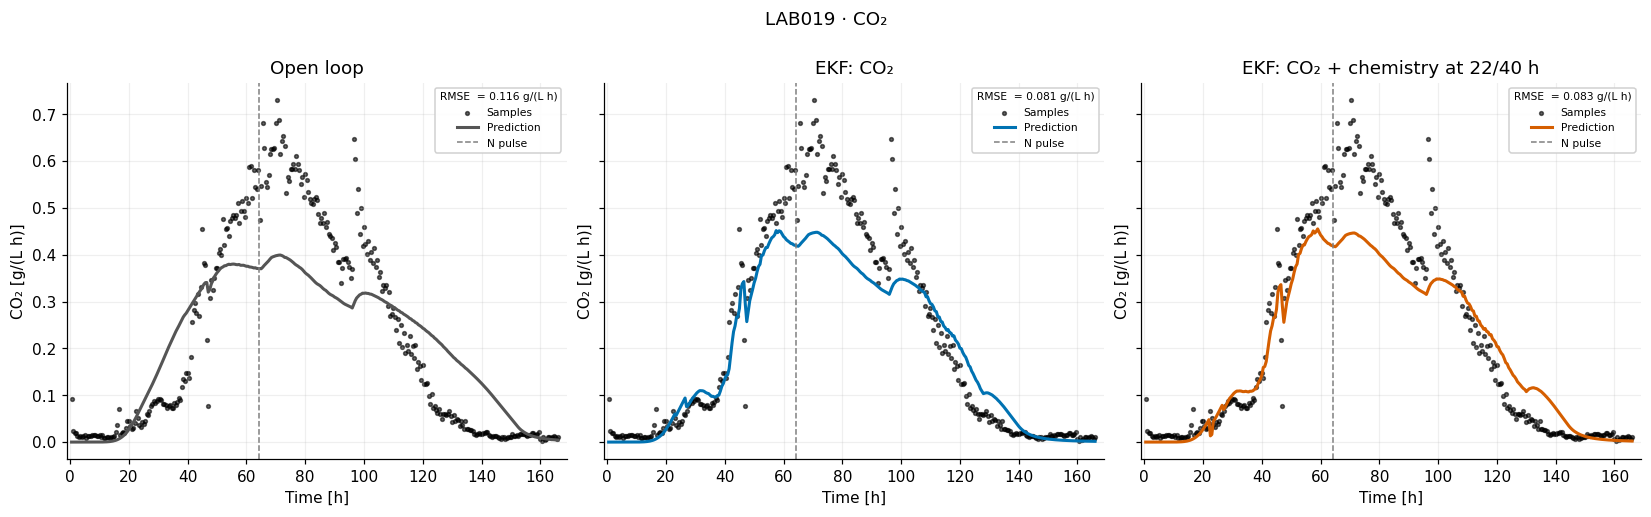

In [6]:
KF_FIGURES={}
def kf_legend(ax,errors=None,unit='g/L'):
 handles,labels=ax.get_legend_handles_labels()
 unique=dict(zip(labels,handles))
 title='\n'.join(f"RMSE {name} = {value:.3f} {unit}" for name,value in (errors or {}).items())
 leg=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=7,
               title=title or None,title_fontsize=7,framealpha=.90)
 assert len(leg.get_texts())==len(unique)

def kf_finish(fig,axs,title,key):
 fig.suptitle(title,y=.995)
 fig.tight_layout(pad=.7,h_pad=1.1,w_pad=.8,rect=(0,0,1,.975))
 assert not fig.legends
 KF_FIGURES[key]=fig
 plt.show()


COLORS={'Libre':'#555555','CO₂':'#0072B2','CO₂ + química':'#D55E00'}
TITLES={'Libre':'Open loop','CO₂':'EKF: CO₂','CO₂ + química':'EKF: CO₂ + chemistry at 22/40 h'}
fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharex=True,sharey=True)
for ax,(name,r) in zip(axes,RUNS.items()):
 valid=gas_obs[gas_obs.valid]
 ax.scatter(valid.t_h,valid.q,s=6,c='black',alpha=.6,label='Samples')
 ax.plot(r['forecast'].t_h,r['forecast'].predicted,color=COLORS[name],lw=2,label='Prediction')
 ax.axvline(TP,color='.5',ls='--',lw=1,label='N pulse')
 ax.set(title=TITLES[name],xlabel='Time [h]',xlim=(-1,HORIZON+3),ylabel='CO₂ [g/(L h)]')
 error=(r['forecast'].predicted-r['forecast'].observed)[gas_obs.valid.to_numpy()]
 kf_legend(ax,{'':float(np.sqrt(np.mean(error**2)))},'g/(L h)')
kf_finish(fig,axes,'LAB019 · CO₂','CO2')


In [7]:
reserved=chem.loc[chem.role.eq('reservada')].copy()
evaluation=[]
for name,r in RUNS.items():
    for _,sample in reserved.iterrows():
        for channel,column in CHANNELS.items():
            if pd.notna(sample[column]):
                censored=channel=='GF' and str(sample.GF_zero_substitution).lower()=='true'
                prediction=np.interp(sample.t_h,r['frame'].index,r['frame'][channel])
                evaluation.append(dict(scenario=name,t_h=sample.t_h,channel=channel,
                    observed=sample[column],predicted=prediction,error=prediction-sample[column],censored=censored))
evaluation=pd.DataFrame(evaluation)
metrics=evaluation[~evaluation.censored].groupby(['scenario','channel']).agg(
    n=('error','size'),RMSE=('error',lambda e:np.sqrt(np.mean(e**2))),MAE=('error',lambda e:np.mean(abs(e)))).reset_index()

LABELS={'GF':('Glucose + fructose','g/L',1.),'N':('YAN','mg/L',1000.),
        'E':('Ethanol','g/L',1.),'X':('Biomass','g/L',1.)}
def complete_curve(channel):
 label,unit,factor=LABELS[channel]
 fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharex=True,sharey=True)
 valid=chem.dropna(subset=[CHANNELS[channel]]).copy()
 if channel=='GF':valid=valid.loc[~valid.GF_zero_substitution.astype(str).str.lower().eq('true')]
 valid=valid.loc[valid.t_h>0]
 for ax,(name,r) in zip(axes,RUNS.items()):
  ax.plot(r['frame'].index,r['frame'][channel]*factor,color=COLORS[name],lw=2,label='Prediction')
  ax.scatter(valid.t_h,valid[CHANNELS[channel]]*factor,c='black',s=25,zorder=5,label='Samples')
  initial=float(r['frame'][channel].iloc[0])*factor
  point=ax.scatter([0.],[initial],c='black',s=25,zorder=5,label='Samples')
  assert np.allclose(point.get_offsets(),[[0.,initial]])
  ax.axvline(TP,color='.5',ls='--',lw=1,label='N pulse')
  ax.set(title=TITLES[name],xlabel='Time [h]',ylabel=f'{label} [{unit}]',xlim=(-1,HORIZON+3))
  m=metrics.loc[metrics.channel.eq(channel)&metrics.scenario.eq(name)].iloc[0]
  kf_legend(ax,{'':float(m.RMSE)*factor},unit)
 kf_finish(fig,axes,f'LAB019 · {label}',channel)


## Curva completa de azúcar total

**Pregunta:** ¿Se reproduce el consumo de azúcar hasta el final? La medición final proviene de un resultado negativo sustituido por cero: se marca como censurada y no entra en el RMSE.

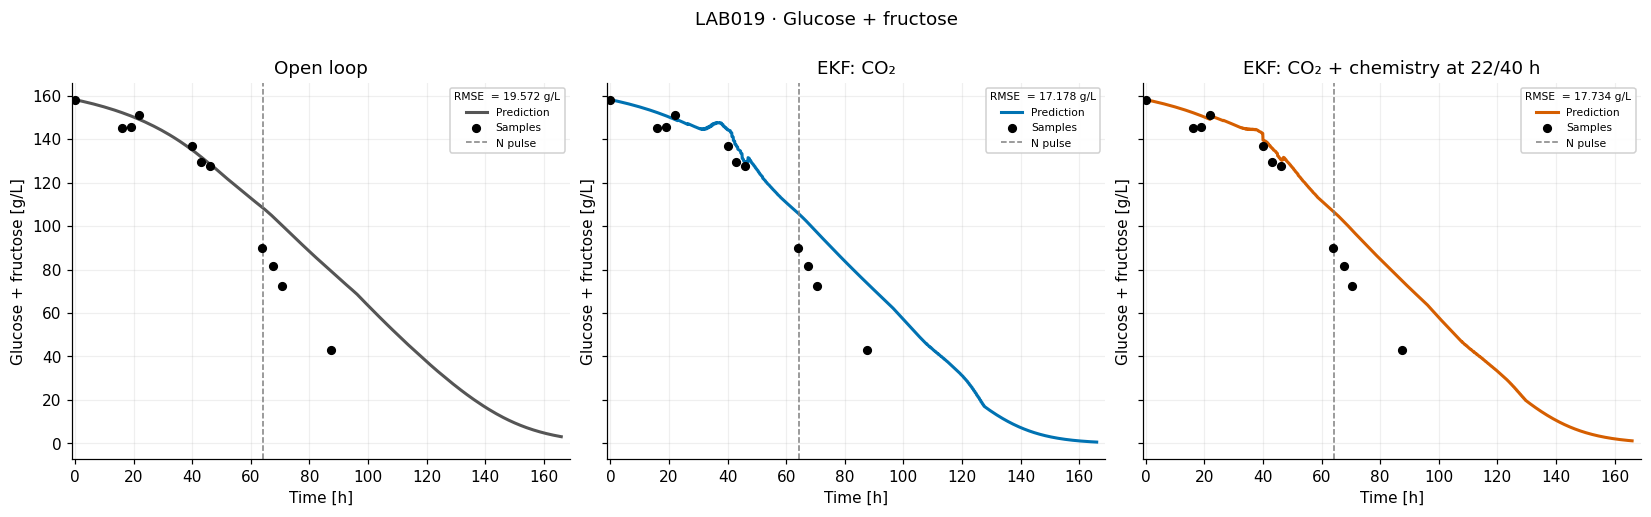

In [8]:
complete_curve('GF')

## Curva completa de nitrógeno

**Pregunta:** ¿Se reproduce el agotamiento y la respuesta al aporte de nitrógeno? Las estrellas rojas son las únicas dos mediciones químicas usadas por el filtro. La nutrición es una entrada conocida, no una medición.

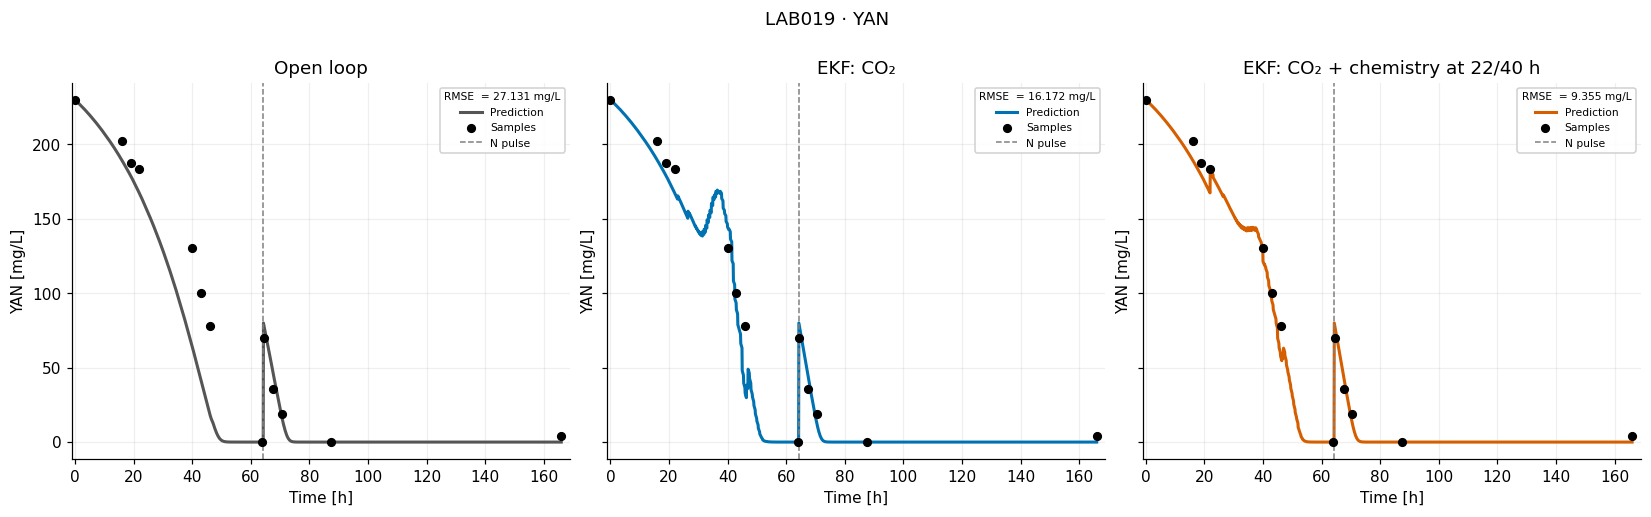

In [9]:
complete_curve('N')

## Curva completa de etanol

**Pregunta:** ¿El etanol predicho concuerda con las muestras que el filtro nunca ha recibido? Aquí todas las mediciones dibujadas son reservadas; no se asimila etanol.

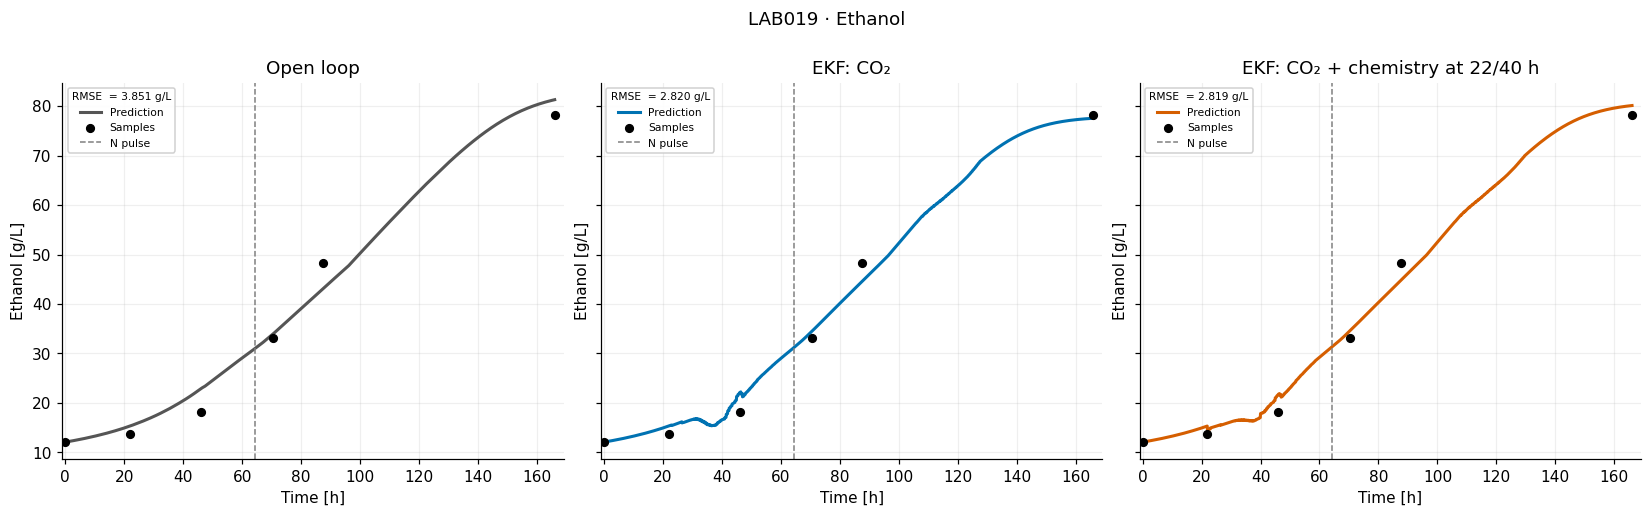

In [10]:
complete_curve('E')

## Curva completa de biomasa viable

**Pregunta:** ¿La biomasa viable estimada sigue el contraste disponible? Oculyze se muestra como referencia con incertidumbre metrológica pendiente; no se usa para ajustar el filtro ni como verdad exacta.

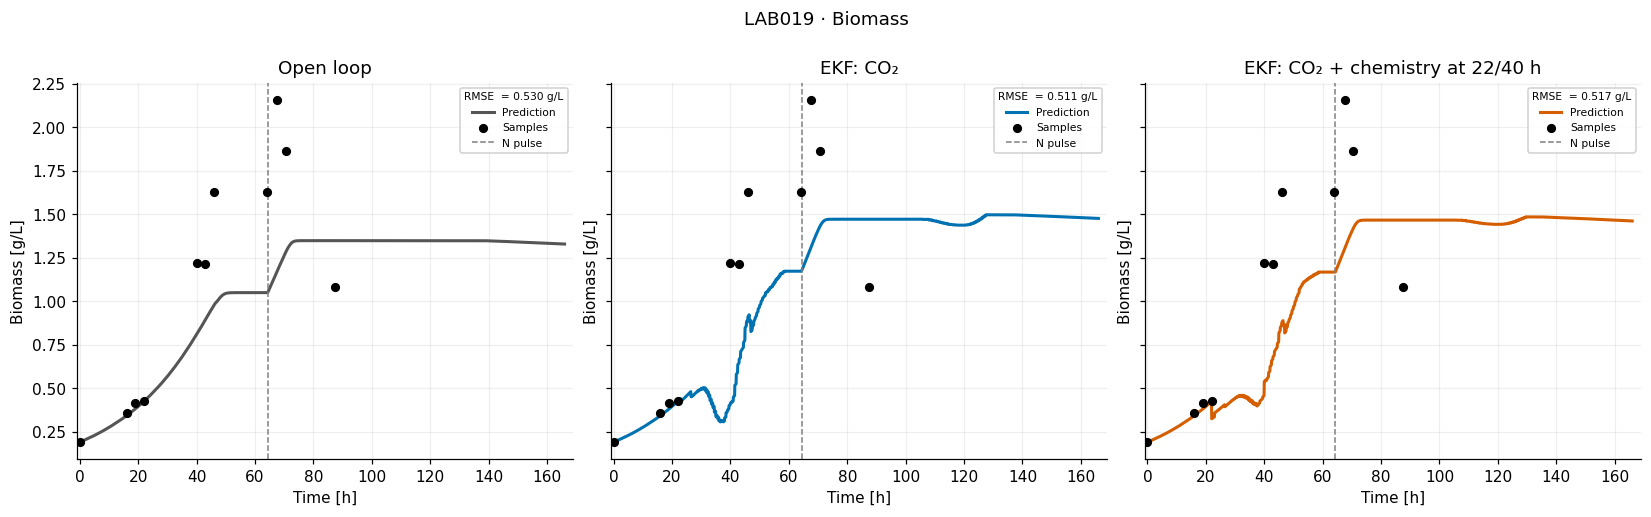

In [11]:
complete_curve('X')

## Qué mejora y qué empeora

La tabla usa sólo muestras reservadas, excluyendo iniciales, muestras de 22/40 h y el azúcar
final censurado. Se separa el tramo inicial del posterior a nutrición para no ocultar el
comportamiento tardío en una única cifra. Un menor error de gas no demuestra mejores estados.

In [12]:
summary=[]
for name,r in RUNS.items():
    d=r['diag']
    err=(r['forecast'].predicted-r['forecast'].observed)[gas_obs.valid.to_numpy()]
    summary.append(dict(escenario=name,RMSE_CO2=float(np.sqrt(np.mean(err**2))),
        correcciones_CO2=0 if d.empty else int(d.channel.eq('CO2').sum()),
        correcciones_quimicas=0 if d.empty else int(d.channel.eq('GF+N').sum()),
        amortiguadas=0 if d.empty else int(d.alpha.lt(.999999).sum()),
        predicciones_negativas=len(r['negative'])))
display(pd.DataFrame(summary))
for row in summary:
    if row['correcciones_CO2']:
        display(Markdown(f"**{TITLES[row['escenario']]}:** {row['amortiguadas']} actualizaciones amortiguadas. "
            'Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; '
            'este prototipo no puede considerarse validado por reducir el RMSE.'))
sections=[]
for label,mask in [('Antes de nutrición',evaluation.t_h<TP),('Después de nutrición',evaluation.t_h>TP)]:
    part=evaluation[mask&~evaluation.censored]
    for (name,ch),d in part.groupby(['scenario','channel']):
        label_ch,unit,factor=LABELS[ch]
        sections.append(dict(tramo=label,variable=label_ch,unidad=unit,escenario=name,n=len(d),
                             RMSE=float(np.sqrt(np.mean(d.error**2)))*factor))
display(pd.DataFrame(sections))
display(Markdown('Los resultados deben interpretarse por variable y por tramo. Las correcciones de 22/40 h '
    'no añaden información química posterior a nutrición. Las discrepancias tardías pueden reflejar la capa '
    'postnutrición heredada, inicialización, incertidumbre omitida o limitaciones del EKF.'))

,escenario,RMSE_CO2,correcciones_CO2,correcciones_quimicas,amortiguadas,predicciones_negativas
0,Libre,0.115674,0,0,0,0
1,CO₂,0.080689,208,0,102,0
2,CO₂ + química,0.082751,208,2,98,0


**EKF: CO₂:** 102 actualizaciones amortiguadas. Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; este prototipo no puede considerarse validado por reducir el RMSE.

**EKF: CO₂ + chemistry at 22/40 h:** 98 actualizaciones amortiguadas. Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; este prototipo no puede considerarse validado por reducir el RMSE.

,tramo,variable,unidad,escenario,n,RMSE
0,Antes de nutrición,Ethanol,g/L,CO₂,1,3.828668
1,Antes de nutrición,Glucose + fructose,g/L,CO₂,5,8.892393
2,Antes de nutrición,YAN,mg/L,CO₂,5,21.944759
3,Antes de nutrición,Biomass,g/L,CO₂,5,0.451932
4,Antes de nutrición,Ethanol,g/L,CO₂ + química,1,3.497626
5,Antes de nutrición,Glucose + fructose,g/L,CO₂ + química,5,9.132814
6,Antes de nutrición,YAN,mg/L,CO₂ + química,5,11.557342
7,Antes de nutrición,Biomass,g/L,CO₂ + química,5,0.460732
8,Antes de nutrición,Ethanol,g/L,Libre,1,4.635840
9,Antes de nutrición,Glucose + fructose,g/L,Libre,5,9.332996


Los resultados deben interpretarse por variable y por tramo. Las correcciones de 22/40 h no añaden información química posterior a nutrición. Las discrepancias tardías pueden reflejar la capa postnutrición heredada, inicialización, incertidumbre omitida o limitaciones del EKF.

## Anexo técnico: matrices, memoria y limitaciones

Estado físico: [X,N,G,F,E,Cd,O₂]. Memoria auxiliar: [X_ref,N_ref,G_ref,F_ref,E_ref],
trayectoria contrafactual sin aporte de N. La fuente gaseosa postnutrición utiliza ambas
trayectorias según la formulación v3 existente; se conserva su kernel causal de normalización
analítica y la rampa de actividad. No hay biomasa muerta ni glicerol en la integración.
La muerte celular conserva su efecto de pérdida en X cuando la cinética lo activa; no se
integra un inventario de biomasa muerta.

P₀ comparte exactamente las incertidumbres iniciales entre las cinco variables biológicas
y su referencia. Q comparte los canales de crecimiento/fermentación entre ambas trayectorias;
la perturbación de Cd es independiente. Se conservan las mismas intensidades exploratorias
del primer ensayo. El pulso de 0,08 g/L se aplica una única vez al N físico y no a N_ref;
su incertidumbre no se estima en este prototipo.

La temperatura es exógena; sus errores no están incluidos en P. Puerta por consumo de azúcar
2–10 g/L, parámetros fijos de transferencia entrenados en LAB016–018, sin reajuste.
La puerta heredada afecta sólo la capa gaseosa y su balance global de carbono sigue pendiente.
Los parámetros fueron calibrados sobre procesamiento offline: su transferencia causal no es
una validación independiente de la arquitectura.

R_CO₂=(0,04 g/L/h)²; R_química=diag[(2 g/L)²,(0,015 g/L)²], orden [GF,N]. Son escalas
de trabajo y no precisiones instrumentales verificadas. Q_d≈Q_c·Δt para pasos de cinco minutos.
Se conserva un acumulador de gas por ventana de 30 min, con covarianza cruzada con el estado.
La actualización es Joseph; las ganancias que intentan cruzar cero se amortiguan y se cuentan.
La positividad no convierte las covarianzas en intervalos calibrados. Los bins bajo el umbral
de detección se omiten, no se interpreta cada cero como una observación gaussiana exacta.

In [13]:
display(Markdown('**P₀ físico (7×7)**'));display(pd.DataFrame(Pphysical,index=PHYSICAL,columns=PHYSICAL))
display(Markdown('**Q_c físico (7×7), y Q_d a cinco minutos**'))
display(pd.DataFrame(Qc[:7,:7],index=PHYSICAL,columns=PHYSICAL))
display(pd.DataFrame(Qc[:7,:7]/12,index=PHYSICAL,columns=PHYSICAL))
display(Markdown('**P₀ completo, incluida la memoria (12×12)**'))
display(pd.DataFrame(P0,index=STATE,columns=STATE))
display(Markdown('**Q_c completo, incluida la memoria (12×12)**'))
display(pd.DataFrame(Qc,index=STATE,columns=STATE))
display(pd.DataFrame(Rchem,index=['GF','N'],columns=['GF','N']))
display(pd.DataFrame(Hchem/SCALE[None,:],index=['GF','N'],columns=STATE))
z=RUNS['CO₂']['frame'].loc[24.,STATE].to_numpy(float)/SCALE
p,q,F,H=linearized(z,24,24+1/12)
display(Markdown('**F físico completo: ejemplo 24 → 24,0833 h**'))
display(pd.DataFrame(F*SCALE[:,None]/SCALE[None,:],index=STATE,columns=STATE))
display(Markdown('**H_CO₂ al completar la ventana respecto a [z,A]:**'))
display(pd.DataFrame([[0.]*NS+[1/BIN_H]],columns=STATE+['A']))
display(choice[['training','stage','kCO2_release_h','CO2sat_scale','matrix_gain']])
display(theta_table[~theta_table.parameter.str.startswith('gamma')][['parameter','theta']])

**P₀ físico (7×7)**

,X,N,G,F,E,Cd,O2
X,0.036437,0.000000,0.0,0.0,0.00,0.0000,0.00000
N,0.000000,0.000225,0.0,0.0,0.00,0.0000,0.00000
G,0.000000,0.000000,1.0,-1.0,0.00,0.0000,0.00000
F,0.000000,0.000000,-1.0,5.0,0.00,0.0000,0.00000
E,0.000000,0.000000,0.0,0.0,0.25,0.0000,0.00000
Cd,0.000000,0.000000,0.0,0.0,0.00,0.0025,0.00000
O2,0.000000,0.000000,0.0,0.0,0.00,0.0000,0.56079


**Q_c físico (7×7), y Q_d a cinco minutos**

,X,N,G,F,E,Cd,O2
X,0.000009,-2.409862e-06,-0.000009,-0.000008,0.000000,0.000000,0.0
N,-0.000002,6.452707e-07,0.000002,0.000002,0.000000,0.000000,0.0
G,-0.000009,2.494440e-06,0.006410,0.000008,-0.001603,-0.001531,0.0
F,-0.000008,2.171251e-06,0.000008,0.006407,-0.004384,-0.004188,0.0
E,0.000000,0.000000e+00,-0.001603,-0.004384,0.003404,0.003251,0.0
Cd,0.000000,0.000000e+00,-0.001531,-0.004188,0.003251,0.003206,0.0
O2,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.0


,X,N,G,F,E,Cd,O2
X,7.500000e-07,-2.008219e-07,-7.763223e-07,-6.757391e-07,0.000000,0.000000,0.0
N,-2.008219e-07,5.377256e-08,2.078700e-07,1.809376e-07,0.000000,0.000000,0.0
G,-7.763223e-07,2.078700e-07,5.341369e-04,6.994551e-07,-0.000134,-0.000128,0.0
F,-6.757391e-07,1.809376e-07,6.994551e-07,5.339422e-04,-0.000365,-0.000349,0.0
E,0.000000e+00,0.000000e+00,-1.335439e-04,-3.652943e-04,0.000284,0.000271,0.0
Cd,0.000000e+00,0.000000e+00,-1.275726e-04,-3.489604e-04,0.000271,0.000267,0.0
O2,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.0


**P₀ completo, incluida la memoria (12×12)**

... (7 outputs left out)

**H_CO₂ al completar la ventana respecto a [z,A]:**

,X,N,G,F,E,Cd,O2,X_ref,N_ref,G_ref,F_ref,E_ref,A
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


,training,stage,kCO2_release_h,CO2sat_scale,matrix_gain
0,train_016_018,Z1,0.424588,0.35139,0.880749


,parameter,theta
0,mu0,0.078728
1,sN,8.751446
2,qN,0.021080
3,qXG,0.081491
4,qXF,0.070933
5,betaG0,0.428878
6,sG,0.097455
7,betaF0,3.440399
8,sF,0.178295
9,qEG,1.712807


## Comprobaciones y trazabilidad

Se verifica el RHS reducido contra las cinco ecuaciones oficiales, la convergencia del paso,
los Jacobianos, el balance del reservorio en cada transición, el pulso único y la invariancia
del filtro frente a cambios de las muestras reservadas. SOURCE no contiene outputs;
EXECUTED contiene las curvas y tablas. El notebook no escribe datos o parámetros históricos.

In [14]:
refined,qr=transition_batch(z,24,24+1/12,internal_h=1/120)
refinement=max(np.max(abs((p-refined[0])*SCALE)),abs(q-qr[0]))
_,_,Fhalf,_=linearized(z,24,24+1/12,eps=5e-6)
fd_error=np.linalg.norm(F-Fhalf)/max(np.linalg.norm(F),1e-12)
assert refinement<1e-4 and fd_error<1e-3,(refinement,fd_error)
saved=chem.copy()
chem.loc[chem.role.eq('reservada'),list(CHANNELS.values())]=999.
control=run_scenario('control',True,True)
chem=saved
invariance=float(np.max(abs(control['frame'][STATE].to_numpy()-RUNS['CO₂ + química']['frame'][STATE].to_numpy())))
assert invariance==0
prefix=RUNS['CO₂']['frame'].index<22.
assert np.array_equal(RUNS['CO₂']['frame'].loc[prefix,STATE],RUNS['CO₂ + química']['frame'].loc[prefix,STATE])
assert all(r['pulse_count']==1 for r in RUNS.values())
for r in RUNS.values():
    f=r['frame'];before=f.index<TP-1e-8
    memory_error=np.max(abs(f.loc[before,PHYSICAL[:5]].to_numpy()-f.loc[before,STATE[7:12]].to_numpy()))
    assert memory_error<1e-6,memory_error
    assert not r['negative'], 'Predicciones negativas: no interpretar como trayectoria física válida'
assert not {'Xd','Gly'}&set(STATE)
assert {str(path.relative_to(ROOT)):sha(path) for path in INPUTS}==HASHES
checks=dict(reduced_rhs_error=float(max(core_errors)),refinement=float(refinement),FD=float(fd_error),
            reserved_invariance=invariance,unique_nutrition=True,physical_states=PHYSICAL,
            final_horizon=HORIZON,input_hashes_verified=True)
display(checks)
TRACE=dict(created_at=datetime.now(ZoneInfo('America/Santiago')).isoformat(),
    executable=sys.executable,state_order=STATE,initial=x0.tolist(),inputs=HASHES,
    theta={k:v for k,v in theta.items() if not k.startswith('gamma')},gas=gas_params,
    P0=P0.tolist(),Qc=Qc.tolist(),Rgas=Rgas,Rchem=Rchem.tolist(),checks=checks)
display(pd.DataFrame(HASHES.items(),columns=['entrada','SHA256']))
print('Verificado: datos intactos, pulso único, química reservada no utilizada, sin commit/push.')

Verificado: datos intactos, pulso único, química reservada no utilizada, sin commit/push.


{'reduced_rhs_error': 2.220446049250313e-16,
 'refinement': 1.539740557277014e-13,
 'FD': 3.1647248988322846e-09,
 'reserved_invariance': 0.0,
 'unique_nutrition': True,
 'physical_states': ['X', 'N', 'G', 'F', 'E', 'Cd', 'O2'],
 'final_horizon': 166.0,
 'input_hashes_verified': True}

,entrada,SHA256
0,data\original\natural\lab019_021\backup_global...,3caf3325257e64fc0d7024a70ff42d69e98bd2c8764a7f...
1,data\original\natural\lab019_021\backup_global...,b5a1528f6f0ee44334a460af396d59ea8456fd67d79b5c...
2,src\wine_fermentation\model.py,98f10708ffe678f7864a76a228b18f11e27302ca6819b9...


Primer EKF: correcciones y amortiguación verificadas; RMSE YAN actualizado incluyendo NUT; ningún parámetro reajustado.


## Auditoría de correcciones: matrices variables y restricción original

**CO₂, t=23 h, alpha=1:** K calculada y aplicada, convertidas a unidades físicas.

,K calculada,K aplicada
X,1.862997,1.862997
N,-0.282484,-0.282484
G,-26.963327,-26.963327
F,-13.741220,-13.741220
E,14.322086,14.322086
Cd,3.930733,3.930733
O2,-3.878179,-3.878179
X_ref,1.862997,1.862997
N_ref,-0.282484,-0.282484
G_ref,-26.963327,-26.963327


,CO₂
CO₂,0.049264


**CO₂, t=36 h, alpha=1:** K calculada y aplicada, convertidas a unidades físicas.

... (16 outputs left out)

,G+F,N
G+F,85.304904,0.549444
N,0.549444,0.004374


**Corrección química a 40 h, alpha=1:**

,G+F,N
X,-0.013608,-1.714801
N,0.001489,0.525870
G,0.269998,28.074544
F,0.260133,-1.605118
E,-0.137865,-16.099004
Cd,-0.005862,-0.766034
O2,-0.012223,-0.478000
X_ref,-0.013608,-1.714801
N_ref,0.001489,0.525870
G_ref,0.269998,28.074544


,G+F,N
G+F,10.342679,0.032479
N,0.032479,0.000577


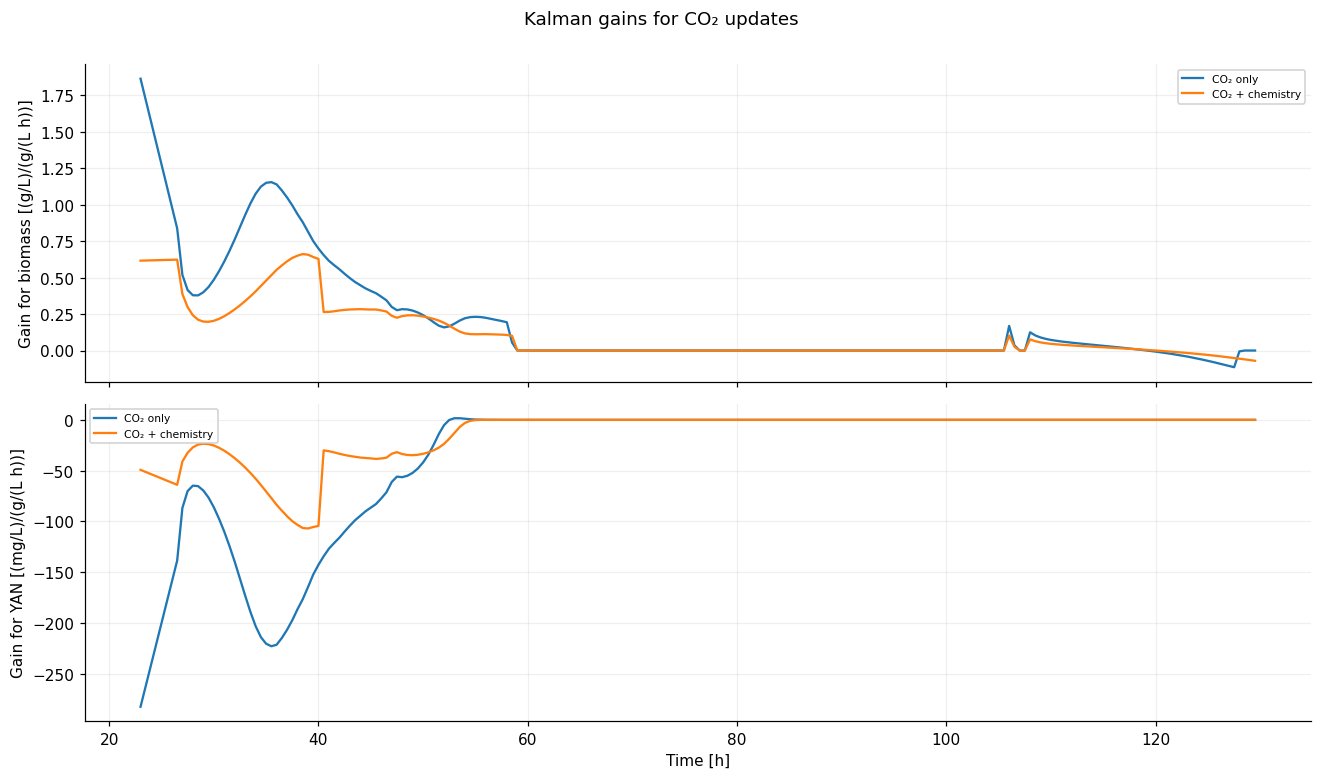

In [15]:
display(Markdown('## Auditoría de correcciones: matrices variables y restricción original'))
for name in ('CO₂','CO₂ + química'):
    d=RUNS[name]['diag']
    selected=d[d.channel.eq('CO2')]
    for time_target in (23.,36.,75.):
        row=selected.iloc[int(np.argmin(abs(selected.t_h.to_numpy()-time_target)))]
        display(Markdown(f"**{name}, t={row.t_h:g} h, alpha={row.alpha:.6g}:** K calculada y aplicada, convertidas a unidades físicas."))
        states=STATE+['Acumulado de gas'] if row.K_used.shape[0]==NA else STATE
        scaling=np.r_[SCALE,1.] if len(states)==NA else SCALE
        display(pd.DataFrame({'K calculada':row.K_raw[:,0]*scaling,'K aplicada':row.K_used[:,0]*scaling},index=states))
        display(pd.DataFrame(row.S,index=['CO₂'],columns=['CO₂']))
    chemical=d[d.channel.eq('GF+N')]
    for _,row in chemical.iterrows():
        display(Markdown(f"**Corrección química a {row.t_h:g} h, alpha={row.alpha:.6g}:**"))
        display(pd.DataFrame(row.K_used*SCALE[:,None],index=STATE,columns=['G+F','N']))
        display(pd.DataFrame(row.S,index=['G+F','N'],columns=['G+F','N']))

fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for name in ('CO₂','CO₂ + química'):
 d=RUNS[name]['diag'];d=d[d.channel.eq('CO2')]
 label='CO₂ only' if name=='CO₂' else 'CO₂ + chemistry'
 axes[0].plot(d.t_h,[k[0,0]*SCALE[0] for k in d.K_used],label=label)
 axes[1].plot(d.t_h,[k[1,0]*SCALE[1]*1000 for k in d.K_used],label=label)
axes[0].set_ylabel('Gain for biomass [(g/L)/(g/(L h))]')
axes[1].set_ylabel('Gain for YAN [(mg/L)/(g/(L h))]');axes[1].set_xlabel('Time [h]')
for ax in axes:kf_legend(ax)
kf_finish(fig,axes,'Kalman gains for CO₂ updates','gains')
# Paridad de conteos de correcciones; evaluación YAN actualizada incluyendo NUT.
for name,amort in [('CO₂',102),('CO₂ + química',98)]:
    d=RUNS[name]['diag'];assert int(d.channel.eq('CO2').sum())==208
    assert int(d.alpha.lt(.999999).sum())==amort
# Archived YAN RMSE excluded NUT and is not the current scoring target.
assert reserved.loc[reserved.is_NUT.astype(str).str.lower().eq('true'),'N_kg_m3'].notna().sum()==1
assert PHYSICAL==['X','N','G','F','E','Cd','O2']
print('Primer EKF: correcciones y amortiguación verificadas; RMSE YAN actualizado incluyendo NUT; ningún parámetro reajustado.')


## Evaluation including the nutrition sample

The reserved YAN RMSE now includes the nutrition-associated sample. Initial and 22/40 h samples retain their existing roles. The correction counts, trajectories, parameters and other-state RMSE are unchanged.

| Case | YAN samples | YAN RMSE [mg/L] |
|---|---:|---:|
| CO₂ | 10 | 16.1722 |
| CO₂ + química | 10 | 9.3553 |
| Libre | 10 | 27.1314 |
